# Страхование путешественников: сегменты клиентов и проверка нового тарифа

**Задача:** исследовать состав страхового портфеля, выплаты и влияние нового подхода к ценообразованию на покупки полисов.

Сначала подготовим данные и опишем сегменты полисов. Затем сравним контрольный тариф с тестовым на основе клиентских событий A/B-эксперимента. Главное решение — есть ли основания распространить новый тариф на всю аудиторию.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, chisquare
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams['font.family'] = 'DejaVu Sans'
clients = pd.read_excel('CASE_CLIENTS.xlsx')
contracts = pd.read_excel('CASE_CONTRACTS.xlsx')
losses = pd.read_excel('CASE_LOSSES.xlsx')
experiment = pd.read_excel('experiment_group.xlsx')
policies = pd.read_excel('policies_cleaned.xlsx')
print('Клиенты:',len(clients),'| Полисы:',len(contracts),'| Выплаты:',len(losses),'| Показанные варианты:',len(experiment))
print('Доступные записи витрины:',len(policies))

Клиенты: 3711 | Полисы: 3711 | Выплаты: 45 | Показанные варианты: 14842
Доступные записи витрины: 3711


## Данные страхового портфеля

В первичных источниках представлены договоры, характеристики страхователей и выплаты. Их объединяет `client_id`; у каждой строки полиса есть идентификатор договора. Для сегментации используется уже подготовленная витрина, в которой суммы приведены к сопоставимой долларовой оценке и есть признак `anomaly`.

In [2]:
joined = contracts.merge(clients[['client_id','age','sex']],on='client_id',how='left')
payouts = losses.groupby('client_id',as_index=False)['loss_payout_amt'].sum()
joined = joined.merge(payouts,on='client_id',how='left')
print('Записей после объединения:',len(joined))
print('Не найдены возраст или пол:',int(joined[['age','sex']].isna().any(axis=1).sum()))
print('Есть выплата:',int(joined.loss_payout_amt.fillna(0).gt(0).sum()))
print('Пустые значения в готовой витрине:',int(policies.isna().sum().sum()))

Записей после объединения: 3711
Не найдены возраст или пол: 0
Есть выплата: 45
Пустые значения в готовой витрине: 0


### Что означает признак аномалии

В готовой витрине 193 записи отмечены как необычные. Проверка показала, что среди них **все 45 полисов с положительными выплатами**. Поэтому механическое исключение аномалий уничтожило бы информацию об убытках. Для построения сегментов сохраняем все строки, а флаг используем для дополнительной проверки результатов.

In [3]:
flag=pd.crosstab(policies['anomaly'],policies['loss_payout_amt_usd']>0)
print('Статус аномалии × положительная выплата:')
print(flag)
assert int((policies.loss_payout_amt_usd>0).sum())==45

Статус аномалии × положительная выплата:
loss_payout_amt_usd  False  True 
anomaly                          
0                     3518      0
1                      148     45


## Сегментация страховых полисов

Используем четыре характеристики, доступные до наступления страхового случая: возраст, длительность, стоимость и страховую сумму. Фактическая выплата не включается в признаки модели — она нужна для оценки профиля готовых групп. Сегментируем **записи о полисах**, не уникальных людей.

In [4]:
features=['age','duration','price_usd','insurance_amount_usd']
seg = policies.dropna(subset=features).copy()
X_scaled = StandardScaler().fit_transform(seg[features])
cluster_model=KMeans(n_clusters=5, random_state=1, n_init=10)
seg['segment']=cluster_model.fit_predict(X_scaled)
print('Полисов в сегментации:',len(seg))
print('Silhouette (случайная выборка 800):',round(silhouette_score(X_scaled,seg.segment,sample_size=800,random_state=1),3))
seg['payout_case']=(seg['loss_payout_amt_usd']>0).astype(int)
profile=seg.groupby('segment').agg(policies=('segment','size'),age=('age','mean'),price_usd=('price_usd','mean'),premiums_usd=('price_usd','sum'),payouts_usd=('loss_payout_amt_usd','sum'),payout_cases=('payout_case','sum'),anomalies=('anomaly','sum'))
profile['payout_to_premiums_pct']=100*profile.payouts_usd/profile.premiums_usd
print(profile.round(1).to_string())

Полисов в сегментации: 3711
Silhouette (случайная выборка 800): 0.491
         policies   age  price_usd  premiums_usd  payouts_usd  payout_cases  anomalies  payout_to_premiums_pct
segment                                                                                                       
0             770  48.9       47.6       36639.4      98630.2            25         85                   269.2
1             111  40.0      786.8       87339.6       5098.5             4         28                     5.8
2            1116  32.0       17.8       19828.7       2039.4             3         19                    10.3
3             870  49.7       17.8       15500.7       6458.1             8         43                    41.7
4             844  32.1       49.1       41398.8      50733.9             5         18                   122.5


**Интерпретация.** Группы отличаются прежде всего возрастом, стоимостью и сроком полиса. В отдельных сегментах отношение выплат к премиям выше 100%, но положительных выплат всего 45 на 3 711 записей. Эти соотношения описывают наблюдаемый портфель и не доказывают причинной роли возраста или тарифа.

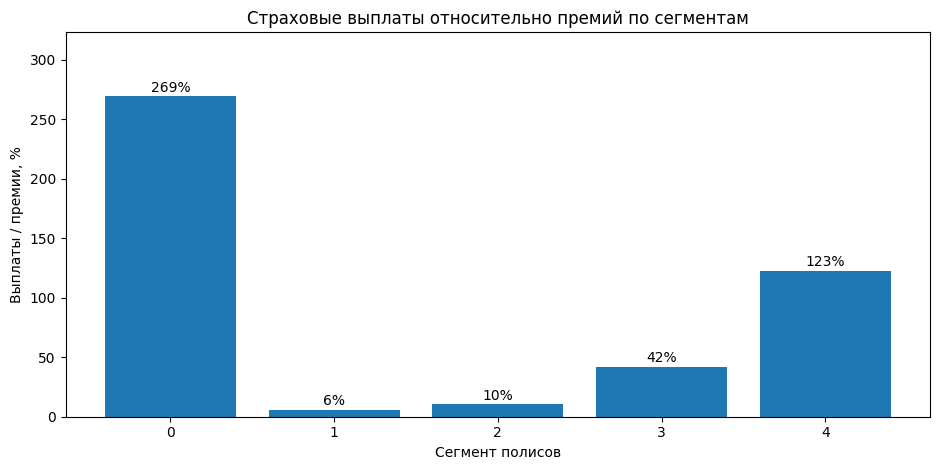

In [5]:
plt.figure(figsize=(9.5,4.8))
bars=plt.bar(profile.index.astype(str),profile.payout_to_premiums_pct)
for v,bar in zip(profile.payout_to_premiums_pct,bars):
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height()+4,f'{v:.0f}%',ha='center')
plt.ylim(0,max(profile.payout_to_premiums_pct)*1.2)
plt.title('Страховые выплаты относительно премий по сегментам')
plt.xlabel('Сегмент полисов');plt.ylabel('Выплаты / премии, %')
plt.tight_layout();plt.savefig('segments.png',dpi=150);plt.show()

## A/B-тест ценообразования

**Control** — традиционная оценка риска. **Test** — тариф на основе сегментации. Анализ проводится на уровне клиентов, которым назначена группа: клиенты без заполненного `group` не смешиваются с контролем или тестом.

Рассчитываем конверсию, среднюю цену купленного полиса, страховые премии и выплаты на клиента. Для сопоставления цен используется курс **80 ₽ за 1 USD**, принятый в данных эксперимента. Валюта исходных выплат не указана; в анализе выплаты трактуются как рублёвые. Эти условия влияют на финансовые выводы.

In [6]:
print('Группы:',experiment.group.value_counts(dropna=False).to_dict())
exp=experiment[experiment.group.isin(['control','test'])].copy()
cs=exp.groupby('group').size();srm=chisquare(cs.values)
print('Сохранено клиентов:',len(exp),'| χ² p-value при сравнении групп:',round(srm.pvalue,5))
contract_pricing=contracts[['client_id','contract_id','currency_name','price']].copy()
contract_pricing['premium_rub']=np.where(contract_pricing.currency_name.eq('Доллар США'),contract_pricing.price*80,contract_pricing.price)
d = exp[['client_id','group']].merge(contract_pricing[['client_id','contract_id','premium_rub']],on='client_id',how='left')
d = d.merge(payouts,on='client_id',how='left')
d['bought']=d.contract_id.notna().astype(int)
d[['premium_rub','loss_payout_amt']]=d[['premium_rub','loss_payout_amt']].fillna(0)
d['net_after_payout_rub']=d.premium_rub-d.loss_payout_amt
print('Клиентов в расчёте:',len(d),'| Купили полис:',int(d.bought.sum()))

Группы: {'test': 6306, 'control': 6043, nan: 2493}
Сохранено клиентов: 12349 | χ² p-value при сравнении групп: 0.01795
Клиентов в расчёте: 12349 | Купили полис: 3616


In [7]:
ab=d.groupby('group').agg(clients=('client_id','size'),purchases=('bought','sum'),premiums_rub=('premium_rub','sum'),payouts_rub=('loss_payout_amt','sum'))
ab['conversion_pct']=100*ab.purchases/ab.clients
ab['avg_purchased_premium_rub']=ab.premiums_rub/ab.purchases
ab['premium_per_client_rub']=ab.premiums_rub/ab.clients
ab['net_per_client_rub']=(ab.premiums_rub-ab.payouts_rub)/ab.clients
ab['payout_to_premiums_pct']=100*ab.payouts_rub/ab.premiums_rub
print(ab.round(2).T.to_string())

group                         control        test
clients                       6043.00     6306.00
purchases                     1949.00     1667.00
premiums_rub               8097229.00  8714866.00
payouts_rub                6380000.00  3440000.00
conversion_pct                  32.25       26.44
avg_purchased_premium_rub     4154.56     5227.87
premium_per_client_rub        1339.94     1382.00
net_per_client_rub             284.17      836.48
payout_to_premiums_pct          78.79       39.47


In [8]:
ctrl=d[d.group.eq('control')];test=d[d.group.eq('test')]
pvals={
 'Конверсия':ttest_ind(ctrl.bought,test.bought,equal_var=False).pvalue,
 'Цена купленного полиса':ttest_ind(ctrl.loc[ctrl.bought.eq(1),'premium_rub'],test.loc[test.bought.eq(1),'premium_rub'],equal_var=False).pvalue,
 'Премии на клиента':ttest_ind(ctrl.premium_rub,test.premium_rub,equal_var=False).pvalue,
 'Выплаты на клиента':ttest_ind(ctrl.loss_payout_amt,test.loss_payout_amt,equal_var=False).pvalue,
 'Результат после выплат на клиента':ttest_ind(ctrl.net_after_payout_rub,test.net_after_payout_rub,equal_var=False).pvalue,
}
for name,p in pvals.items(): print(f'{name}: p={p:.6g}')

Конверсия: p=1.25851e-12
Цена купленного полиса: p=0.0104185
Премии на клиента: p=0.739113
Выплаты на клиента: p=0.257603
Результат после выплат на клиента: p=0.23497


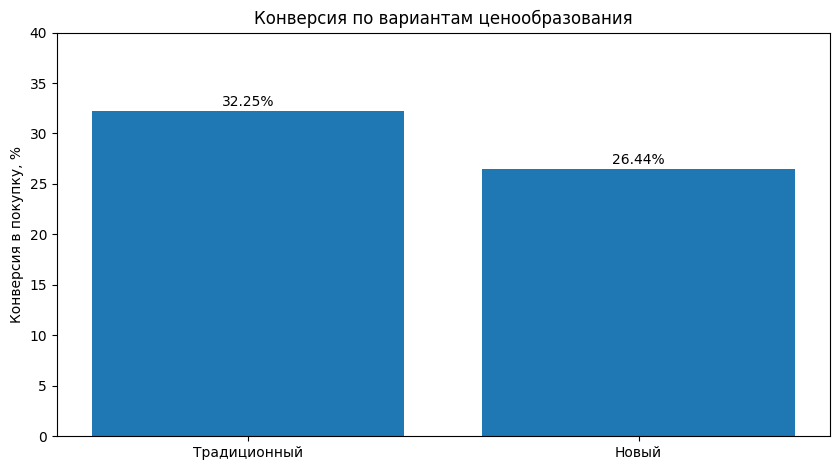

In [9]:
plt.figure(figsize=(8.5,4.8))
conv=ab.loc[['control','test'],'conversion_pct']
bars=plt.bar(['Традиционный','Новый'],conv.values)
for v,bar in zip(conv.values,bars):plt.text(bar.get_x()+bar.get_width()/2,v+.5,f'{v:.2f}%',ha='center')
plt.ylim(0,40);plt.ylabel('Конверсия в покупку, %');plt.title('Конверсия по вариантам ценообразования')
plt.tight_layout();plt.savefig('conversion.png',dpi=160);plt.show()

## Решение

**Новый тариф пока не стоит распространять на всю аудиторию.** В тестовой группе конверсия снизилась примерно на **5,82 процентного пункта** (p < 0,001). Средняя цена купленного полиса выросла, однако различие по премиям на клиента и финансовому результату после выплат **статистически не подтверждено**.

Перед следующим запуском необходимо проверить причины снижения конверсии, записи с незаполненной группой (2 493 клиентов), валюту выплат и полноту событий покупки. Сегменты пригодны для дальнейшей проверки тарифных гипотез, но не являются доказательством улучшения нового ценообразования.